In [2]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


In [3]:
import tensorflow as tf

dataset_path = "dataset"

train_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    image_size=(224, 224),
    batch_size=8,
    shuffle=True
)

print("Classes:", train_dataset.class_names)

Found 62 files belonging to 4 classes.
Classes: ['damaged road', 'garbage', 'pipe_leakage', 'pothole']


In [5]:
import sys
!"{sys.executable}" -m pip install matplotlib

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 762.0 kB/s eta 0:00:12
   -- ------------------------------------- 0.5/9.3 MB 762.0 kB/s eta 0:00:12
   --- ------------------------------------ 0.8/9.3 MB 699.0 kB/s eta 0:00:13
   --- ------------------------------------ 0.8/9.3 MB 699.0 kB/s eta 0:00:13
   ---- ----------------------------------- 1.0/9.3 MB 671.0 kB/s eta 0:00:13
   ---- ----------------------------------- 1.0/9.3 MB 671.0 kB/s eta 0:00:13
   ----- ---------------------------------- 1.3/9.3 MB 645.3 kB/s eta 0:00:13
   ----- ---------------------------------- 1.3/9.3 MB 645.3 kB/s eta 0:00:13
   ------ --------------------------------- 1.6/9.3 MB 650.2 kB/s eta 0:00:12
   ------ --------------------------------- 1.6/9.3 MB 650.2 kB/s eta 0:00:12
   ------- --

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\SNEHAL C THOMBARE\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


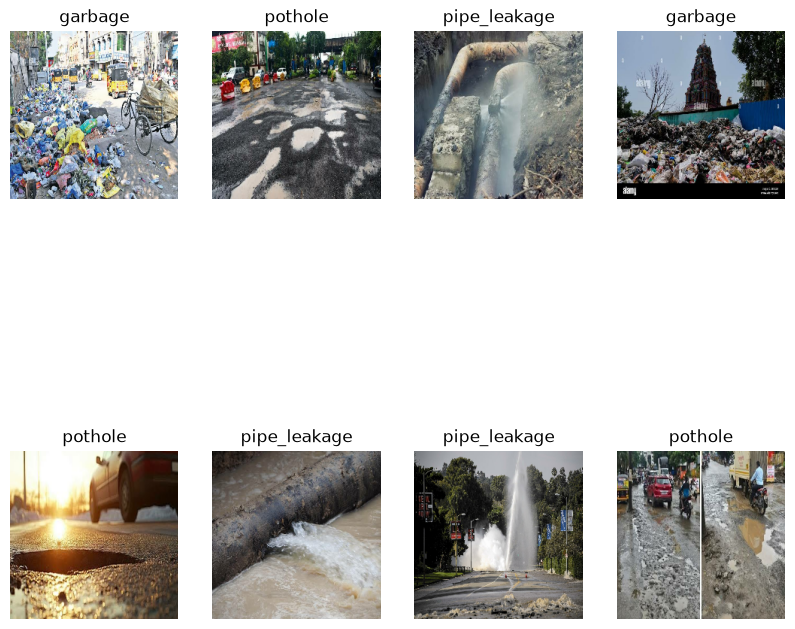

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

for images, labels in train_dataset.take(1):
    for i in range(min(8, len(images))):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(train_dataset.class_names[labels[i]])
        plt.axis("off")

plt.show()

In [8]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    "dataset",
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(224, 224),
    batch_size=8
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    "dataset",
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(224, 224),
    batch_size=8
)

print("Classes:", train_dataset.class_names)

Found 62 files belonging to 4 classes.
Using 50 files for training.
Found 62 files belonging to 4 classes.
Using 12 files for validation.
Classes: ['damaged road', 'garbage', 'pipe_leakage', 'pothole']


In [9]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.cache().shuffle(100).prefetch(buffer_size=AUTOTUNE)

validation_dataset = validation_dataset.cache().prefetch(buffer_size=AUTOTUNE)

print("Dataset is ready for training!")

Dataset is ready for training!


In [10]:
from tensorflow.keras import layers, models

model = models.Sequential([
    
    # Resize image pixel values from 0-255 to 0-1
    layers.Rescaling(1./255, input_shape=(224, 224, 3)),
    
    # First feature detection layer
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(),
    
    # Second feature detection layer
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(),
    
    # Third feature detection layer
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(),
    
    # Convert features into one list
    layers.Flatten(),
    
    # Learning layer
    layers.Dense(128, activation='relu'),
    
    # Final output: 4 classes
    layers.Dense(4, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

C:\Users\SNEHAL C THOMBARE\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)                │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 86528)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      11,075,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 4)                   │             516 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 11,169,476 (42.61 MB)

 Trainable params: 11,169,476 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10
)

Epoch 1/10


C:\Users\SNEHAL C THOMBARE\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 357ms/step - accuracy: 0.3400 - loss: 2.4350 - val_accuracy: 0.5833 - val_loss: 1.3319
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 280ms/step - accuracy: 0.2800 - loss: 1.4126 - val_accuracy: 0.3333 - val_loss: 1.3716
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 280ms/step - accuracy: 0.4200 - loss: 1.3204 - val_accuracy: 0.5000 - val_loss: 1.1954
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 301ms/step - accuracy: 0.5600 - loss: 1.1505 - val_accuracy: 0.0000e+00 - val_loss: 1.5258
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 276ms/step - accuracy: 0.5600 - loss: 0.9938 - val_accuracy: 0.5833 - val_loss: 0.9726
Epoch 6/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 277ms/step - accuracy: 0.8200 - loss: 0.6561 - val_accuracy: 0.8333 - val_loss: 0.9599
Epoch 7/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 281ms/step - accuracy: 0.9200 - loss: 0.4849 - val_accuracy: 0.6667 - val_loss: 1.0043
Epoch 8/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 278ms/step - accuracy: 0.9400 - loss: 0.2319 - val_accuracy: 0.5833 - val_loss: 1.3548

In [13]:
class_names = [
    'damaged road',
    'garbage',
    'pipe_leakage',
    'pothole'
]

print(class_names)

['damaged road', 'garbage', 'pipe_leakage', 'pothole']


In [14]:
model.save("road_problem_model.keras")

In [15]:
import os

print(os.listdir())

['.ipynb_checkpoints', 'dataset', 'Problem_Detection_Model.ipynb', 'road_problem_model.keras']


In [16]:
import os

print(os.listdir("test_images"))

['1.jpg']


In [18]:
import sys
!"{sys.executable}" -m pip install pillow


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\SNEHAL C THOMBARE\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [20]:
import sys
!"{sys.executable}" -m pip install --upgrade pillow


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\SNEHAL C THOMBARE\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [21]:
from PIL import Image

print("Pillow is working!")

Pillow is working!


In [22]:
import tensorflow as tf
import numpy as np
from PIL import Image

# Load saved trained model
model = tf.keras.models.load_model("road_problem_model.keras")

# Class names
class_names = [
    "damaged road",
    "garbage",
    "pipe_leakage",
    "pothole"
]

# Load test image
img = Image.open("test_images/1.jpg").convert("RGB")

# Resize image
img = img.resize((224, 224))

# Convert to NumPy array
img_array = np.array(img)

# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

# Predict
predictions = model.predict(img_array)

# Get prediction
predicted_index = np.argmax(predictions[0])
predicted_class = class_names[predicted_index]
confidence = predictions[0][predicted_index] * 100

print("Predicted Problem:", predicted_class)
print("Confidence:", round(confidence, 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 274ms/step
Predicted Problem: damaged road
Confidence: 53.88 %


In [23]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Data augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

# Load MobileNetV2 without its final classification layer
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers for first training
base_model.trainable = False

# Build improved model
improved_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    
    data_augmentation,
    
    layers.Rescaling(1./127.5, offset=-1),
    
    base_model,
    
    layers.GlobalAveragePooling2D(),
    
    layers.Dropout(0.3),
    
    layers.Dense(4, activation="softmax")
])

# Compile model
improved_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

improved_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 13s 1us/step


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)            │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling_1 (Rescaling)              │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 4)                   │           5,124 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [24]:
history_improved = improved_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10
)

Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 17s 790ms/step - accuracy: 0.2800 - loss: 1.6639 - val_accuracy: 0.5833 - val_loss: 1.3559
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 228ms/step - accuracy: 0.4000 - loss: 1.5077 - val_accuracy: 0.4167 - val_loss: 1.2252
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 206ms/step - accuracy: 0.4600 - loss: 1.3136 - val_accuracy: 0.4167 - val_loss: 1.2264
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 205ms/step - accuracy: 0.6600 - loss: 1.0678 - val_accuracy: 0.5833 - val_loss: 1.0274
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 203ms/step - accuracy: 0.6200 - loss: 0.8898 - val_accuracy: 0.5833 - val_loss: 0.8593
Epoch 6/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 206ms/step - accuracy: 0.7400 - loss: 0.8260 - val_accuracy: 0.6667 - val_loss: 0.8296
Epoch 7/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 220ms/step - accuracy: 0.7400 - loss: 0.6660 - val_accuracy: 0.6667 - val_loss: 0.8531
Epoch 8/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 214ms/step - accuracy: 0.7600 - loss: 0.6612 - val_accuracy: 0.7500 - val_loss

In [25]:
print("Final Training Accuracy:", history_improved.history["accuracy"][-1] * 100)
print("Final Validation Accuracy:", history_improved.history["val_accuracy"][-1] * 100)

print("Best Validation Accuracy:", max(history_improved.history["val_accuracy"]) * 100)

Final Training Accuracy: 75.99999904632568
Final Validation Accuracy: 83.33333134651184
Best Validation Accuracy: 83.33333134651184


In [26]:
improved_model.save("improved_road_problem_model.keras")

print("Improved model saved successfully!")

Improved model saved successfully!


In [27]:
improved_model.save("improved_road_problem_model.keras")

print("Improved model saved successfully!")

Improved model saved successfully!


In [28]:
import tensorflow as tf
import numpy as np
from PIL import Image

# Load improved saved model
improved_model = tf.keras.models.load_model(
    "improved_road_problem_model.keras"
)

# Class names
class_names = [
    "damaged road",
    "garbage",
    "pipe_leakage",
    "pothole"
]

# Load test image
img = Image.open("test_images/1.jpg").convert("RGB")

# Resize
img = img.resize((224, 224))

# Convert image to array
img_array = np.array(img)

# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

# Predict
predictions = improved_model.predict(img_array)

# Get prediction
predicted_index = np.argmax(predictions[0])
predicted_class = class_names[predicted_index]
confidence = predictions[0][predicted_index] * 100

print("Predicted Problem:", predicted_class)
print("Confidence:", round(confidence, 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
Predicted Problem: damaged road
Confidence: 41.09 %


In [29]:
import os

for folder in os.listdir("dataset"):
    folder_path = os.path.join("dataset", folder)
    if os.path.isdir(folder_path):
        print(folder, "=", len(os.listdir(folder_path)), "images")

.ipynb_checkpoints = 0 images
damaged road = 10 images
garbage = 21 images
pipe_leakage = 22 images
pothole = 12 images


In [30]:
import os

for folder in os.listdir("dataset"):
    folder_path = os.path.join("dataset", folder)

    if os.path.isdir(folder_path) and folder != ".ipynb_checkpoints":
        images = [
            f for f in os.listdir(folder_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]
        print(folder, "=", len(images), "images")

damed_road = 98 images
garbage = 99 images
open-manthole = 65 images
pipe_leakage = 89 images
stright -light issue = 33 images
trees-fall-down = 33 images


In [31]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 16

train_dataset = tf.keras.utils.image_dataset_from_directory(
    "dataset",
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    "dataset",
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Save class names BEFORE prefetching
class_names = train_dataset.class_names

print("Classes:", class_names)

Found 421 files belonging to 6 classes.
Using 337 files for training.
Found 421 files belonging to 6 classes.
Using 84 files for validation.
Classes: ['damaged_road', 'garbage', 'open-manthole', 'pipe_leakage', 'stright -light issue', 'trees-fall-down']


In [32]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.cache().shuffle(500).prefetch(AUTOTUNE)
validation_dataset = validation_dataset.cache().prefetch(AUTOTUNE)

print("Dataset optimized successfully!")

Dataset optimized successfully!


In [33]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Data augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

# Load MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained model
base_model.trainable = False

# Build model
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    
    data_augmentation,
    
    # MobileNetV2 preprocessing
    layers.Rescaling(1./127.5, offset=-1),
    
    base_model,
    
    layers.GlobalAveragePooling2D(),
    
    layers.Dropout(0.3),
    
    # 6 categories
    layers.Dense(6, activation="softmax")
])

# Compile
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential_3 (Sequential)            │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling_2 (Rescaling)              │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 6)                   │           7,686 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [34]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10
)

Epoch 1/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 13s 293ms/step - accuracy: 0.2700 - loss: 1.8940 - val_accuracy: 0.5357 - val_loss: 1.2415
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 218ms/step - accuracy: 0.5074 - loss: 1.2633 - val_accuracy: 0.6310 - val_loss: 0.9827
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 252ms/step - accuracy: 0.6172 - loss: 1.0498 - val_accuracy: 0.7500 - val_loss: 0.7875
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 251ms/step - accuracy: 0.6884 - loss: 0.8374 - val_accuracy: 0.7500 - val_loss: 0.7648
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 250ms/step - accuracy: 0.7389 - loss: 0.7268 - val_accuracy: 0.7976 - val_loss: 0.6862
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 241ms/step - accuracy: 0.7537 - loss: 0.6804 - val_accuracy: 0.8095 - val_loss: 0.6881
Epoch 7/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 251ms/step - accuracy: 0.7774 - loss: 0.6132 - val_accuracy: 0.8333 - val_loss: 0.6308
Epoch 8/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 248ms/step - accuracy: 0.7953 - loss: 0.6020 - val_accuracy: 0

In [35]:
print("Final Training Accuracy:", round(history.history["accuracy"][-1] * 100, 2), "%")
print("Final Validation Accuracy:", round(history.history["val_accuracy"][-1] * 100, 2), "%")
print("Best Validation Accuracy:", round(max(history.history["val_accuracy"]) * 100, 2), "%")

Final Training Accuracy: 85.46 %
Final Validation Accuracy: 80.95 %
Best Validation Accuracy: 83.33 %


In [36]:
model.save("civic_issue_detection_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [37]:
img = Image.open("test_images/1.jpg").convert("RGB")

In [38]:
import tensorflow as tf
import numpy as np
from PIL import Image

# Load your new 6-category model
model = tf.keras.models.load_model("civic_issue_detection_model.keras")

# Same class order used during training
class_names = [
    "damaged_road",
    "garbage",
    "open-manthole",
    "pipe_leakage",
    "stright -light issue",
    "trees-fall-down"
]

# Load your existing test image
img = Image.open("test_images/1.jpg").convert("RGB")

# Resize image
img = img.resize((224, 224))

# Convert to array
img_array = np.array(img)
img_array = np.expand_dims(img_array, axis=0)

# Predict
predictions = model.predict(img_array)

# Best prediction
predicted_index = np.argmax(predictions[0])
predicted_class = class_names[predicted_index]
confidence = predictions[0][predicted_index] * 100

print("Predicted Issue:", predicted_class)
print("Confidence:", round(confidence, 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Predicted Issue: damaged_road
Confidence: 97.53 %


In [39]:
import os
import tensorflow as tf
import numpy as np
from PIL import Image

# Load model
model = tf.keras.models.load_model("civic_issue_detection_model.keras")

# Class names - SAME order as training
class_names = [
    "damaged_road",
    "garbage",
    "open-manthole",
    "pipe_leakage",
    "stright -light issue",
    "trees-fall-down"
]

# Folder containing test images
test_folder = "test_images"

# Loop through all images
for filename in os.listdir(test_folder):
    
    if filename.lower().endswith((".jpg", ".jpeg", ".png")):
        
        image_path = os.path.join(test_folder, filename)
        
        # Load image
        img = Image.open(image_path).convert("RGB")
        img = img.resize((224, 224))
        
        # Convert to array
        img_array = np.array(img)
        img_array = np.expand_dims(img_array, axis=0)
        
        # Predict
        predictions = model.predict(img_array, verbose=0)
        
        predicted_index = np.argmax(predictions[0])
        predicted_class = class_names[predicted_index]
        confidence = predictions[0][predicted_index] * 100
        
        print("\nImage:", filename)
        print("Predicted Issue:", predicted_class)
        print("Confidence:", round(confidence, 2), "%")
        print("-" * 40)


Image: 1.jpg
Predicted Issue: damaged_road
Confidence: 97.53 %
----------------------------------------

Image: 2.png
Predicted Issue: damaged_road
Confidence: 45.55 %
----------------------------------------

Image: 3.jpg
Predicted Issue: trees-fall-down
Confidence: 95.39 %
----------------------------------------

Image: 4.jpg
Predicted Issue: stright -light issue
Confidence: 92.78 %
----------------------------------------

Image: 5.jpg
Predicted Issue: pipe_leakage
Confidence: 96.46 %
----------------------------------------

Image: 6.png
Predicted Issue: damaged_road
Confidence: 45.55 %
----------------------------------------


In [40]:
import os
import tensorflow as tf
import numpy as np
from PIL import Image

model = tf.keras.models.load_model("civic_issue_detection_model.keras")

class_names = [
    "damaged_road",
    "garbage",
    "open-manthole",
    "pipe_leakage",
    "stright -light issue",
    "trees-fall-down"
]

test_folder = "test_images"
THRESHOLD = 70

for filename in os.listdir(test_folder):

    if filename.lower().endswith((".jpg", ".jpeg", ".png")):

        image_path = os.path.join(test_folder, filename)

        img = Image.open(image_path).convert("RGB")
        img = img.resize((224, 224))

        img_array = np.array(img)
        img_array = np.expand_dims(img_array, axis=0)

        predictions = model.predict(img_array, verbose=0)

        predicted_index = np.argmax(predictions[0])
        confidence = predictions[0][predicted_index] * 100

        print("\nImage:", filename)

        if confidence >= THRESHOLD:
            print("Detected Issue:", class_names[predicted_index])
            print("Confidence:", round(confidence, 2), "%")
            print("Status: Automatically detected ✅")
        else:
            print("Detected Issue: Unknown / Manual Review Required")
            print("Highest Prediction:", class_names[predicted_index])
            print("Confidence:", round(confidence, 2), "%")
            print("Status: Needs human verification ⚠️")

        print("-" * 45)


Image: 1.jpg
Detected Issue: damaged_road
Confidence: 97.53 %
Status: Automatically detected ✅
---------------------------------------------

Image: 2.png
Detected Issue: Unknown / Manual Review Required
Highest Prediction: damaged_road
Confidence: 45.55 %
Status: Needs human verification ⚠️
---------------------------------------------

Image: 3.jpg
Detected Issue: trees-fall-down
Confidence: 95.39 %
Status: Automatically detected ✅
---------------------------------------------

Image: 4.jpg
Detected Issue: stright -light issue
Confidence: 92.78 %
Status: Automatically detected ✅
---------------------------------------------

Image: 5.jpg
Detected Issue: pipe_leakage
Confidence: 96.46 %
Status: Automatically detected ✅
---------------------------------------------

Image: 6.png
Detected Issue: Unknown / Manual Review Required
Highest Prediction: damaged_road
Confidence: 45.55 %
Status: Needs human verification ⚠️
---------------------------------------------


NameError: name 'model' is not defined

In [4]:
import os

folder = "dataset/broken_footpath"

images = [
    f for f in os.listdir(folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
]

print("Broken footpath images:", len(images))

Broken footpath images: 37


FileNotFoundError: [WinError 3] The system cannot find the path specified: 'C:\\Users\\SNEHAL C THOMBARE\\PublicComplaintAI\\static\\dataset\\blocked_drain'

In [3]:

import os

# Find folders named "blocked_drain" inside your PublicComplaintAI project
base = r"C:\Users\SNEHAL C THOMBARE"

for root, dirs, files in os.walk(base):
    if "blocked_drain" in dirs:
        path = os.path.join(root, "blocked_drain")
        print("FOUND:", path)


In [5]:
import os

dataset = "dataset"

total = 0

for category in sorted(os.listdir(dataset)):
    folder = os.path.join(dataset, category)

    if os.path.isdir(folder):
        images = [
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
        ]

        print(f"{category}: {len(images)}")
        total += len(images)

print("\nTOTAL IMAGES:", total)

.ipynb_checkpoints: 0
broken_footpath: 37
broken_streetlight: 31
construction_debris: 20
contaminated_water: 26
damaged_park_equipment: 25
damaged_traffic_signal: 17
damp_or_seepage: 18
dead_animal: 15
exposed_wire: 11
fallen_tree: 33
flooding: 19
footpath_encroachment: 10
garbage_overflow: 94
illegal_dumping: 4
illegal_parking: 13
open_manhole: 61
pothole: 93
public_toilet_unusable: 15
road_crack: 2
sewage_overflow: 0
stray_animal_concern: 15
unhygienic_food_stall: 11
water_leakage: 83

TOTAL IMAGES: 653


In [6]:
import os
from PIL import Image

dataset = "dataset"

total = 0
valid = 0
corrupted = 0

for category in sorted(os.listdir(dataset)):
    folder = os.path.join(dataset, category)

    if not os.path.isdir(folder) or category == ".ipynb_checkpoints":
        continue

    count = 0

    for file in os.listdir(folder):
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
            total += 1
            count += 1

            try:
                img = Image.open(os.path.join(folder, file))
                img.verify()
                valid += 1
            except:
                corrupted += 1

    print(f"{category}: {count}")

print("\n===== DATASET QUALITY =====")
print("Total images:", total)
print("Valid images:", valid)
print("Corrupted images:", corrupted)

broken_footpath: 37
broken_streetlight: 31
construction_debris: 20
contaminated_water: 26
damaged_park_equipment: 25
damaged_traffic_signal: 17
damp_or_seepage: 18
dead_animal: 15
exposed_wire: 11
fallen_tree: 33
flooding: 19
footpath_encroachment: 10
garbage_overflow: 94
illegal_dumping: 4
illegal_parking: 13
open_manhole: 61
pothole: 93
public_toilet_unusable: 15
road_crack: 2
stray_animal_concern: 15
unhygienic_food_stall: 11
water_leakage: 83

===== DATASET QUALITY =====
Total images: 653
Valid images: 653
Corrupted images: 0


In [7]:
import os

dataset = "dataset"

categories = []

for category in sorted(os.listdir(dataset)):
    folder = os.path.join(dataset, category)

    if os.path.isdir(folder) and category != ".ipynb_checkpoints":
        images = [
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
        ]

        if len(images) > 0:
            categories.append(category)

print("Number of categories:", len(categories))
print("\nCategories:")
for i, category in enumerate(categories):
    print(i, ":", category)

Number of categories: 22

Categories:
0 : broken_footpath
1 : broken_streetlight
2 : construction_debris
3 : contaminated_water
4 : damaged_park_equipment
5 : damaged_traffic_signal
6 : damp_or_seepage
7 : dead_animal
8 : exposed_wire
9 : fallen_tree
10 : flooding
11 : footpath_encroachment
12 : garbage_overflow
13 : illegal_dumping
14 : illegal_parking
15 : open_manhole
16 : pothole
17 : public_toilet_unusable
18 : road_crack
19 : stray_animal_concern
20 : unhygienic_food_stall
21 : water_leakage


In [8]:
import os

dataset = "dataset"

categories = []

for category in sorted(os.listdir(dataset)):
    folder = os.path.join(dataset, category)

    if os.path.isdir(folder) and category != ".ipynb_checkpoints":
        images = [
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
        ]

        if len(images) > 0:
            categories.append(category)

print("Total categories:", len(categories))

for i, category in enumerate(categories):
    print(i, ":", category)

Total categories: 22
0 : broken_footpath
1 : broken_streetlight
2 : construction_debris
3 : contaminated_water
4 : damaged_park_equipment
5 : damaged_traffic_signal
6 : damp_or_seepage
7 : dead_animal
8 : exposed_wire
9 : fallen_tree
10 : flooding
11 : footpath_encroachment
12 : garbage_overflow
13 : illegal_dumping
14 : illegal_parking
15 : open_manhole
16 : pothole
17 : public_toilet_unusable
18 : road_crack
19 : stray_animal_concern
20 : unhygienic_food_stall
21 : water_leakage


In [9]:
print("Total categories:", len(categories))

for i, category in enumerate(categories):
    print(i, ":", category)

Total categories: 22
0 : broken_footpath
1 : broken_streetlight
2 : construction_debris
3 : contaminated_water
4 : damaged_park_equipment
5 : damaged_traffic_signal
6 : damp_or_seepage
7 : dead_animal
8 : exposed_wire
9 : fallen_tree
10 : flooding
11 : footpath_encroachment
12 : garbage_overflow
13 : illegal_dumping
14 : illegal_parking
15 : open_manhole
16 : pothole
17 : public_toilet_unusable
18 : road_crack
19 : stray_animal_concern
20 : unhygienic_food_stall
21 : water_leakage


In [10]:
import os
import shutil
import random

random.seed(42)

source = "dataset"
split_dir = "dataset_split"

train_dir = os.path.join(split_dir, "train")
val_dir = os.path.join(split_dir, "validation")

# Create folders
for category in categories:
    os.makedirs(os.path.join(train_dir, category), exist_ok=True)
    os.makedirs(os.path.join(val_dir, category), exist_ok=True)

# Split each category
for category in categories:
    folder = os.path.join(source, category)

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ]

    random.shuffle(images)

    # 80% training, 20% validation
    split_point = int(len(images) * 0.8)

    train_images = images[:split_point]
    val_images = images[split_point:]

    for img in train_images:
        shutil.copy2(
            os.path.join(folder, img),
            os.path.join(train_dir, category, img)
        )

    for img in val_images:
        shutil.copy2(
            os.path.join(folder, img),
            os.path.join(val_dir, category, img)
        )

    print(
        f"{category}: "
        f"{len(train_images)} train, "
        f"{len(val_images)} validation"
    )

print("\n✅ Dataset split completed.")

broken_footpath: 29 train, 8 validation
broken_streetlight: 24 train, 7 validation
construction_debris: 16 train, 4 validation
contaminated_water: 20 train, 6 validation
damaged_park_equipment: 20 train, 5 validation
damaged_traffic_signal: 13 train, 4 validation
damp_or_seepage: 14 train, 4 validation
dead_animal: 12 train, 3 validation
exposed_wire: 8 train, 3 validation
fallen_tree: 26 train, 7 validation
flooding: 15 train, 4 validation
footpath_encroachment: 8 train, 2 validation
garbage_overflow: 75 train, 19 validation
illegal_dumping: 3 train, 1 validation
illegal_parking: 10 train, 3 validation
open_manhole: 48 train, 13 validation
pothole: 74 train, 19 validation
public_toilet_unusable: 12 train, 3 validation
road_crack: 1 train, 1 validation
stray_animal_concern: 12 train, 3 validation
unhygienic_food_stall: 8 train, 3 validation
water_leakage: 66 train, 17 validation

✅ Dataset split completed.


In [11]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: []


In [13]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 16

train_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset_split/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset_split/validation",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names

print("Number of classes:", len(class_names))
print("Classes:", class_names)

Found 513 files belonging to 22 classes.
Found 139 files belonging to 22 classes.
Number of classes: 22
Classes: ['broken_footpath', 'broken_streetlight', 'construction_debris', 'contaminated_water', 'damaged_park_equipment', 'damaged_traffic_signal', 'damp_or_seepage', 'dead_animal', 'exposed_wire', 'fallen_tree', 'flooding', 'footpath_encroachment', 'garbage_overflow', 'illegal_dumping', 'illegal_parking', 'open_manhole', 'pothole', 'public_toilet_unusable', 'road_crack', 'stray_animal_concern', 'unhygienic_food_stall', 'water_leakage']


In [14]:
print("Jupyter is working!")

Jupyter is working!


In [15]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Data augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

# MobileNetV2 base model
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained layers
base_model.trainable = False

# Build model
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1./127.5, offset=-1),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(22, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 22)                  │          28,182 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,286,166 (8.72 MB)

 Trainable params: 28,182 (110.09 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [16]:
EPOCHS = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/10


C:\Users\SNEHAL C THOMBARE\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


33/33 ━━━━━━━━━━━━━━━━━━━━ 23s 380ms/step - accuracy: 0.1657 - loss: 3.1281 - val_accuracy: 0.3381 - val_loss: 2.3606
Epoch 2/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 9s 283ms/step - accuracy: 0.3996 - loss: 2.0223 - val_accuracy: 0.5036 - val_loss: 1.8251
Epoch 3/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 9s 276ms/step - accuracy: 0.5341 - loss: 1.5306 - val_accuracy: 0.5180 - val_loss: 1.5560
Epoch 4/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 10s 292ms/step - accuracy: 0.6238 - loss: 1.1914 - val_accuracy: 0.5683 - val_loss: 1.4317
Epoch 5/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 10s 283ms/step - accuracy: 0.7154 - loss: 0.9619 - val_accuracy: 0.5612 - val_loss: 1.3522
Epoch 6/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 10s 292ms/step - accuracy: 0.7602 - loss: 0.8255 - val_accuracy: 0.5612 - val_loss: 1.3619
Epoch 7/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 12s 371ms/step - accuracy: 0.7602 - loss: 0.7982 - val_accuracy: 0.5612 - val_loss: 1.3432
Epoch 8/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 10s 303ms/step - accuracy: 0.7739 - loss: 0.7038 - val_accuracy: 0.5827 

In [18]:
import numpy as np
import tensorflow as tf

y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Total validation images:", len(y_true))
print("Correct predictions:", np.sum(y_true == y_pred))
print("Wrong predictions:", np.sum(y_true != y_pred))
print("Validation accuracy:", round(np.mean(y_true == y_pred) * 100, 2), "%")

Total validation images: 139
Correct predictions: 82
Wrong predictions: 57
Validation accuracy: 58.99 %


In [19]:
for i, category in enumerate(class_names):
    mask = y_true == i
    total = np.sum(mask)
    correct = np.sum(y_pred[mask] == i)

    if total > 0:
        accuracy = correct / total * 100
        print(f"{category}: {correct}/{total} correct ({accuracy:.1f}%)")

broken_footpath: 1/8 correct (12.5%)
broken_streetlight: 5/7 correct (71.4%)
construction_debris: 4/4 correct (100.0%)
contaminated_water: 2/6 correct (33.3%)
damaged_park_equipment: 4/5 correct (80.0%)
damaged_traffic_signal: 1/4 correct (25.0%)
damp_or_seepage: 3/4 correct (75.0%)
dead_animal: 2/3 correct (66.7%)
exposed_wire: 1/3 correct (33.3%)
fallen_tree: 2/7 correct (28.6%)
flooding: 1/4 correct (25.0%)
footpath_encroachment: 1/2 correct (50.0%)
garbage_overflow: 18/19 correct (94.7%)
illegal_dumping: 0/1 correct (0.0%)
illegal_parking: 0/3 correct (0.0%)
open_manhole: 10/13 correct (76.9%)
pothole: 13/19 correct (68.4%)
public_toilet_unusable: 0/3 correct (0.0%)
road_crack: 0/1 correct (0.0%)
stray_animal_concern: 3/3 correct (100.0%)
unhygienic_food_stall: 1/3 correct (33.3%)
water_leakage: 10/17 correct (58.8%)


In [20]:
model.save("public_complaint_model_v1.keras")
print("✅ Current model safely saved")

✅ Current model safely saved


In [21]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers

# Stronger data augmentation
data_augmentation_v2 = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
])

# Create class weights based on training-image counts
class_counts = []

for category in class_names:
    folder = os.path.join("dataset_split", "train", category)

    count = len([
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ])

    class_counts.append(count)

total_train = sum(class_counts)

class_weights = {}

for i, count in enumerate(class_counts):
    class_weights[i] = total_train / (len(class_names) * count)

print("Class weights:")
for i, category in enumerate(class_names):
    print(category, ":", round(class_weights[i], 2))

Class weights:
broken_footpath : 0.81
broken_streetlight : 0.97
construction_debris : 1.46
contaminated_water : 1.17
damaged_park_equipment : 1.17
damaged_traffic_signal : 1.8
damp_or_seepage : 1.67
dead_animal : 1.95
exposed_wire : 2.92
fallen_tree : 0.9
flooding : 1.56
footpath_encroachment : 2.92
garbage_overflow : 0.31
illegal_dumping : 7.79
illegal_parking : 2.34
open_manhole : 0.49
pothole : 0.32
public_toilet_unusable : 1.95
road_crack : 23.36
stray_animal_concern : 1.95
unhygienic_food_stall : 2.92
water_leakage : 0.35


In [22]:
# Cap very large class weights
class_weights_v2 = {
    i: min(weight, 4.0)
    for i, weight in class_weights.items()
}

print("Version 2 class weights:")
for i, category in enumerate(class_names):
    print(category, ":", round(class_weights_v2[i], 2))

Version 2 class weights:
broken_footpath : 0.81
broken_streetlight : 0.97
construction_debris : 1.46
contaminated_water : 1.17
damaged_park_equipment : 1.17
damaged_traffic_signal : 1.8
damp_or_seepage : 1.67
dead_animal : 1.95
exposed_wire : 2.92
fallen_tree : 0.9
flooding : 1.56
footpath_encroachment : 2.92
garbage_overflow : 0.31
illegal_dumping : 4.0
illegal_parking : 2.34
open_manhole : 0.49
pothole : 0.32
public_toilet_unusable : 1.95
road_crack : 4.0
stray_animal_concern : 1.95
unhygienic_food_stall : 2.92
water_leakage : 0.35


In [23]:
# Build Version 2 model

base_model_v2 = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model_v2.trainable = False

model_v2 = tf.keras.Sequential([
    tf.keras.Input(shape=(224, 224, 3)),
    data_augmentation_v2,
    tf.keras.layers.Rescaling(1./127.5, offset=-1),
    base_model_v2,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(22, activation="softmax")
])

model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("✅ Version 2 model ready")

✅ Version 2 model ready


In [24]:
history_v2 = model_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weights_v2
)

Epoch 1/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 21s 362ms/step - accuracy: 0.0838 - loss: 3.6271 - val_accuracy: 0.1295 - val_loss: 2.9463
Epoch 2/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 10s 300ms/step - accuracy: 0.1423 - loss: 2.8142 - val_accuracy: 0.2518 - val_loss: 2.5510
Epoch 3/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 10s 306ms/step - accuracy: 0.2047 - loss: 2.4461 - val_accuracy: 0.3237 - val_loss: 2.3401
Epoch 4/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 11s 318ms/step - accuracy: 0.2924 - loss: 2.0546 - val_accuracy: 0.3885 - val_loss: 2.0840
Epoch 5/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 12s 350ms/step - accuracy: 0.3723 - loss: 1.8091 - val_accuracy: 0.4317 - val_loss: 1.9052
Epoch 6/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 10s 292ms/step - accuracy: 0.4503 - loss: 1.5430 - val_accuracy: 0.4820 - val_loss: 1.8388
Epoch 7/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 11s 328ms/step - accuracy: 0.4678 - loss: 1.4313 - val_accuracy: 0.5396 - val_loss: 1.6948
Epoch 8/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 11s 340ms/step - accuracy: 0.5205 - loss: 1.2909 - val_accu

In [25]:
val_loss_v2, val_accuracy_v2 = model_v2.evaluate(val_ds)

print("Version 2 Validation Loss:", val_loss_v2)
print("Version 2 Validation Accuracy:", round(val_accuracy_v2 * 100, 2), "%")

9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 209ms/step - accuracy: 0.6043 - loss: 1.3390
Version 2 Validation Loss: 1.339003086090088
Version 2 Validation Accuracy: 60.43 %


In [28]:
import os
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np

image_path = r"C:\Users\SNEHAL C THOMBARE\PublicComplaintAI\test_images\1.jpg"

img = load_img(image_path, target_size=(224, 224))
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# MobileNetV2 preprocessing
img_array = img_array / 127.5 - 1.0

predictions = model_v2.predict(img_array, verbose=0)

predicted_index = np.argmax(predictions[0])
predicted_category = class_names[predicted_index]
confidence = predictions[0][predicted_index] * 100

print("Image:", os.path.basename(image_path))
print("Predicted Category:", predicted_category)
print("Confidence:", round(confidence, 2), "%")

Image: 1.jpg
Predicted Category: broken_streetlight
Confidence: 68.25 %


In [29]:
import os
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array

test_folder = r"C:\Users\SNEHAL C THOMBARE\PublicComplaintAI\test_images"

files = [
    f for f in os.listdir(test_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
]

print("Testing", len(files), "images...\n")

for file in sorted(files):
    image_path = os.path.join(test_folder, file)

    img = load_img(image_path, target_size=(224, 224))
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = img_array / 127.5 - 1.0

    predictions = model_v2.predict(img_array, verbose=0)

    index = np.argmax(predictions[0])
    category = class_names[index]
    confidence = predictions[0][index] * 100

    print(f"{file:20} → {category:30} ({confidence:.2f}%)")

Testing 7 images...

1.jpg                → broken_streetlight             (68.25%)
2.png                → broken_streetlight             (67.82%)
3.jpg                → broken_streetlight             (64.96%)
4.jpg                → broken_streetlight             (66.15%)
5.jpg                → broken_streetlight             (64.00%)
6.png                → broken_streetlight             (67.82%)
images (6).jpg       → broken_streetlight             (60.45%)


In [30]:
import os
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array

test_folder = r"C:\Users\SNEHAL C THOMBARE\PublicComplaintAI\test_images"

files = [
    f for f in os.listdir(test_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
]

for file in sorted(files):
    image_path = os.path.join(test_folder, file)

    img = load_img(image_path, target_size=(224, 224))
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = img_array / 127.5 - 1.0

    predictions = model_v2.predict(img_array, verbose=0)[0]

    top3 = np.argsort(predictions)[-3:][::-1]

    print(f"\n{file}")
    for i in top3:
        print(f"  {class_names[i]:30} {predictions[i]*100:.2f}%")


1.jpg
  broken_streetlight             68.25%
  damp_or_seepage                9.36%
  pothole                        3.93%

2.png
  broken_streetlight             67.82%
  damp_or_seepage                9.66%
  pothole                        3.90%

3.jpg
  broken_streetlight             64.96%
  damp_or_seepage                9.04%
  pothole                        4.91%

4.jpg
  broken_streetlight             66.15%
  damp_or_seepage                9.76%
  pothole                        4.52%

5.jpg
  broken_streetlight             64.00%
  damp_or_seepage                10.02%
  pothole                        4.47%

6.png
  broken_streetlight             67.82%
  damp_or_seepage                9.66%
  pothole                        3.90%

images (6).jpg
  broken_streetlight             60.45%
  damp_or_seepage                13.12%
  pothole                        4.76%


In [31]:
model_v2.save("public_complaint_model_v2_backup.keras")
print("✅ V2 backup saved")

✅ V2 backup saved


In [33]:
# VERSION 3 — Fine-tuning MobileNetV2

# Unfreeze only the last 30 layers of MobileNetV2
base_model_v2.trainable = True

for layer in base_model_v2.layers[:-30]:
    layer.trainable = False

# Recompile with a VERY small learning rate
model_v3 = model_v2

model_v3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("✅ Version 3 ready")
print("Trainable layers:", sum(layer.trainable for layer in base_model_v2.layers))

✅ Version 3 ready
Trainable layers: 30


In [34]:
history_v3 = model_v3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights_v2,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ]
)

Epoch 1/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 38s 588ms/step - accuracy: 0.4094 - loss: 1.5129 - val_accuracy: 0.6259 - val_loss: 1.3209
Epoch 2/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 17s 463ms/step - accuracy: 0.4211 - loss: 1.4616 - val_accuracy: 0.6331 - val_loss: 1.3124
Epoch 3/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 21s 462ms/step - accuracy: 0.4522 - loss: 1.3524 - val_accuracy: 0.6331 - val_loss: 1.3032
Epoch 4/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 20s 458ms/step - accuracy: 0.4795 - loss: 1.2902 - val_accuracy: 0.6331 - val_loss: 1.2970
Epoch 5/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 16s 461ms/step - accuracy: 0.4951 - loss: 1.2171 - val_accuracy: 0.6331 - val_loss: 1.2889
Epoch 6/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 16s 458ms/step - accuracy: 0.5361 - loss: 1.1411 - val_accuracy: 0.6403 - val_loss: 1.2838
Epoch 7/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 16s 471ms/step - accuracy: 0.5302 - loss: 1.1232 - val_accuracy: 0.6403 - val_loss: 1.2775
Epoch 8/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 16s 460ms/step - accuracy: 0.5828 - loss: 1.0820 - val_accu

In [36]:
val_loss_v3, val_accuracy_v3 = model_v3.evaluate(val_ds)

print("Version 3 Validation Accuracy:",
      round(val_accuracy_v3 * 100, 2), "%")

9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 246ms/step - accuracy: 0.6619 - loss: 1.2596
Version 3 Validation Accuracy: 66.19 %


In [37]:
model_v3.save("public_complaint_model_v3.keras")
print("✅ V3 model saved successfully!")

✅ V3 model saved successfully!


In [38]:
predictions = model_v2.predict(img_array, verbose=0)[0]

Testing 7 images with V3...


1.jpg
  broken_streetlight             76.57%
  damp_or_seepage                5.80%
  stray_animal_concern           3.68%

2.png
  broken_streetlight             77.41%
  damp_or_seepage                5.78%
  stray_animal_concern           3.17%

3.jpg
  broken_streetlight             75.63%
  damp_or_seepage                5.93%
  stray_animal_concern           3.95%

4.jpg
  broken_streetlight             75.92%
  damp_or_seepage                5.89%
  stray_animal_concern           3.86%

5.jpg
  broken_streetlight             74.38%
  damp_or_seepage                6.31%
  stray_animal_concern           4.12%

6.png
  broken_streetlight             77.41%
  damp_or_seepage                5.78%
  stray_animal_concern           3.17%

images (6).jpg
  broken_streetlight             71.50%
  damp_or_seepage                7.96%
  stray_animal_concern           4.18%


In [41]:
import os
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array

correct = 0
total = 0

for category in class_names:

    folder = os.path.join("dataset", category)

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ]

    if len(images) == 0:
        continue

    # Take the first image from this category
    file = sorted(images)[0]
    image_path = os.path.join(folder, file)

    img = load_img(image_path, target_size=(224, 224))
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = img_array / 127.5 - 1.0

    predictions = model_v3.predict(img_array, verbose=0)[0]

    predicted_index = np.argmax(predictions)
    predicted_category = class_names[predicted_index]

    is_correct = predicted_category == category

    if is_correct:
        correct += 1

    total += 1

    print(
        f"{category:30} → "
        f"{predicted_category:30} "
        f"{'✅' if is_correct else '❌'}"
    )

print("\n==============================")
print("Categories tested:", total)
print("Correct:", correct)
print("Wrong:", total - correct)
print("Accuracy:", round(correct / total * 100, 2), "%")

broken_footpath                → broken_streetlight             ❌
broken_streetlight             → broken_streetlight             ✅
construction_debris            → broken_streetlight             ❌
contaminated_water             → broken_streetlight             ❌
damaged_park_equipment         → broken_streetlight             ❌
damaged_traffic_signal         → broken_streetlight             ❌
damp_or_seepage                → broken_streetlight             ❌
dead_animal                    → broken_streetlight             ❌
exposed_wire                   → broken_streetlight             ❌
fallen_tree                    → broken_streetlight             ❌
flooding                       → broken_streetlight             ❌
footpath_encroachment          → broken_streetlight             ❌
garbage_overflow               → broken_streetlight             ❌
illegal_dumping                → broken_streetlight             ❌
illegal_parking                → broken_streetlight             ❌
open_manho

In [42]:
import os
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array

test_folder = r"C:\Users\SNEHAL C THOMBARE\PublicComplaintAI\test_images"

files = [
    f for f in os.listdir(test_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
]

print("Testing", len(files), "images with V3...\n")

for file in sorted(files):
    image_path = os.path.join(test_folder, file)

    img = load_img(image_path, target_size=(224, 224))
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    # IMPORTANT:
    # Do NOT normalize here.
    # The model already has its Rescaling layer.

    predictions = model_v3.predict(img_array, verbose=0)[0]

    top3 = np.argsort(predictions)[-3:][::-1]

    print(f"\n{file}")
    for i in top3:
        print(f"  {class_names[i]:30} {predictions[i] * 100:.2f}%")

Testing 7 images with V3...


1.jpg
  pothole                        89.79%
  fallen_tree                    1.82%
  flooding                       1.59%

2.png
  open_manhole                   37.79%
  broken_footpath                33.55%
  pothole                        10.00%

3.jpg
  fallen_tree                    75.02%
  open_manhole                   7.19%
  broken_streetlight             2.98%

4.jpg
  broken_streetlight             86.95%
  exposed_wire                   2.65%
  damaged_park_equipment         2.43%

5.jpg
  water_leakage                  76.45%
  damp_or_seepage                8.39%
  garbage_overflow               3.22%

6.png
  open_manhole                   37.79%
  broken_footpath                33.55%
  pothole                        10.00%

images (6).jpg
  stray_animal_concern           78.81%
  dead_animal                    7.13%
  garbage_overflow               4.63%


In [43]:
img_array = img_array / 127.5 - 1.0

In [44]:
import os
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array

correct = 0
total = 0

for category in class_names:

    folder = os.path.join("dataset", category)

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ]

    if not images:
        continue

    file = sorted(images)[0]
    image_path = os.path.join(folder, file)

    img = load_img(image_path, target_size=(224, 224))
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    # No manual normalization
    predictions = model_v3.predict(img_array, verbose=0)[0]

    predicted_index = np.argmax(predictions)
    predicted_category = class_names[predicted_index]

    is_correct = predicted_category == category

    if is_correct:
        correct += 1

    total += 1

    print(
        f"{category:30} → "
        f"{predicted_category:30} "
        f"{'✅' if is_correct else '❌'}"
    )

print("\n==============================")
print("Categories tested:", total)
print("Correct:", correct)
print("Wrong:", total - correct)
print("Accuracy:", round(correct / total * 100, 2), "%")

broken_footpath                → broken_footpath                ✅
broken_streetlight             → broken_streetlight             ✅
construction_debris            → construction_debris            ✅
contaminated_water             → contaminated_water             ✅
damaged_park_equipment         → damaged_park_equipment         ✅
damaged_traffic_signal         → damaged_traffic_signal         ✅
damp_or_seepage                → damp_or_seepage                ✅
dead_animal                    → dead_animal                    ✅
exposed_wire                   → exposed_wire                   ✅
fallen_tree                    → fallen_tree                    ✅
flooding                       → damaged_park_equipment         ❌
footpath_encroachment          → footpath_encroachment          ✅
garbage_overflow               → garbage_overflow               ✅
illegal_dumping                → garbage_overflow               ❌
illegal_parking                → illegal_parking                ✅
open_manho

In [45]:
import shutil

shutil.copy2(
    "public_complaint_model_v3.keras",
    "public_complaint_model_v3_backup.keras"
)

print("✅ Model backup created")

✅ Model backup created


In [1]:
import os
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array

# Use one known pothole image
folder = "dataset/pothole"

file = [
    f for f in os.listdir(folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
][0]

image_path = os.path.join(folder, file)

img = load_img(image_path, target_size=(224, 224))
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# DO NOT normalize here.
# V3 model already contains its Rescaling layer.

prediction = model_v3.predict(img_array, verbose=0)[0]

index = np.argmax(prediction)

print("Actual category:   pothole")
print("Predicted category:", class_names[index])
print("Confidence:        ", round(prediction[index] * 100, 2), "%")

NameError: name 'model_v3' is not defined

In [2]:
import tensorflow as tf

model_v3 = tf.keras.models.load_model("public_complaint_model_v3.keras")

print("✅ V3 model loaded")
print("Model output:", model_v3.output_shape)

✅ V3 model loaded
Model output: (None, 22)


In [3]:
import os
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array

folder = "dataset/pothole"

file = [
    f for f in os.listdir(folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
][0]

image_path = os.path.join(folder, file)

img = load_img(image_path, target_size=(224, 224))
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# IMPORTANT: no normalization here
prediction = model_v3.predict(img_array, verbose=0)[0]

index = np.argmax(prediction)

print("Actual category:   pothole")
print("Predicted category:", class_names[index])
print("Confidence:        ", round(prediction[index] * 100, 2), "%")

Actual category:   pothole


NameError: name 'class_names' is not defined

In [4]:
class_names = [
    "broken_footpath",
    "broken_streetlight",
    "construction_debris",
    "contaminated_water",
    "damaged_park_equipment",
    "damaged_traffic_signal",
    "damp_or_seepage",
    "dead_animal",
    "exposed_wire",
    "fallen_tree",
    "flooding",
    "footpath_encroachment",
    "garbage_overflow",
    "illegal_dumping",
    "illegal_parking",
    "open_manhole",
    "pothole",
    "public_toilet_unusable",
    "road_crack",
    "stray_animal_concern",
    "unhygienic_food_stall",
    "water_leakage"
]

print("✅ 22 class names loaded")

✅ 22 class names loaded
